# Lab Sheet 02

Harsh Saini | Roll 253028036

MCA III Semester, Session 2026-2027

Run all cells in order from this folder. Outputs below are captured from execution, not typed examples. See README for dataset sources.

## Common setup
Run once before Program 1.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Run this file or notebook from the practicals folder.
DATA = Path("datasets")
OUT = Path("outputs") / "lab_02"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 78)
pd.set_option("display.max_columns", 8)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
np.set_printoptions(precision=3, suppress=True)
sns.set_theme(style="whitegrid", font_scale=0.9)

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=160)
    plt.show()


## Program 01: Load a dataset and identify missing values in each column.

**Procedure:** Load employees.csv and count missing entries.

In [2]:
try:
    original = pd.read_csv(DATA / "employees.csv")
except (FileNotFoundError, pd.errors.ParserError) as error:
    raise RuntimeError("Check datasets/employees.csv") from error
print("Shape:", original.shape)
print(original.isna().sum())


Shape: (20, 7)
age             1
salary          1
experience      0
department      1
joined          0
bonus          12
performance     0
dtype: int64


**Observation:** This small teaching dataset deliberately contains missing data and a salary outlier.

## Program 02: Display the percentage of missing values in every feature.

**Procedure:** Divide missing counts by the number of rows and multiply by 100.

In [3]:
print((original.isna().mean() * 100).round(1))


age            5.000
salary         5.000
experience     0.000
department     5.000
joined         0.000
bonus         60.000
performance    0.000
dtype: float64


**Observation:** The bonus column has 60% missing values.

## Program 03: Remove rows containing missing values from the dataset.

**Procedure:** Drop rows containing any missing value and compare row counts.

In [4]:
complete_rows = original.dropna()
print("Before:", len(original))
print("After:", len(complete_rows))
print(complete_rows.head())


Before: 20
After: 8
      age     salary  experience department      joined    bonus  \
12 32.000  46000.000           8         HR  2023-01-01 4000.000   
13 36.000 250000.000          12      Sales  2023-02-01 5000.000   
14 23.000  27000.000           2         IT  2023-03-01 2000.000   
15 34.000  49000.000          10         HR  2023-04-01 4500.000   
16 28.000  36000.000           5      Sales  2023-05-01 3000.000   

    performance  
12           72  
13           81  
14           58  
15           79  
16           67  


**Observation:** Removing every incomplete row loses many records in this example.

## Program 04: Remove columns having more than 50% missing values.

**Procedure:** Compute the missing fraction and keep columns at or below 0.50.

In [5]:
kept = original.loc[:, original.isna().mean() <= 0.50].copy()
print("Kept:", kept.columns.tolist())
print("Dropped:", original.columns.difference(kept.columns).tolist())


Kept: ['age', 'salary', 'experience', 'department', 'joined', 'performance']
Dropped: ['bonus']


**Observation:** Only columns with more than 50% missing values are removed.

## Program 05: Replace missing numerical values using the mean.

**Procedure:** Copy the data and fill missing numerical values with column means.

In [6]:
mean_filled = original.copy()
columns = mean_filled.select_dtypes(include="number").columns
mean_filled[columns] = mean_filled[columns].fillna(
    mean_filled[columns].mean())
print(mean_filled[columns].head(8))
print("Missing numeric values:",
      mean_filled[columns].isna().sum().sum())


     age    salary  experience    bonus  performance
0 22.000 25000.000           1 3462.500           55
1 25.000 30000.000           3 3462.500           61
2 28.000 35000.000           5 3462.500           64
3 31.000 40000.000           7 3462.500           70
4 35.000 50000.000          10 3462.500           77
5 28.842 45000.000           8 3462.500           74
6 26.000 49157.895           4 3462.500           66
7 29.000 37000.000           6 3462.500           68
Missing numeric values: 0


**Observation:** The salary outlier influences the mean used for filling.

## Program 06: Replace missing numerical values using the median.

**Procedure:** Fill numerical missing values using column medians.

In [7]:
median_filled = original.copy()
columns = median_filled.select_dtypes(include="number").columns
median_filled[columns] = median_filled[columns].fillna(
    median_filled[columns].median())
print(median_filled[columns].head(8))


     age    salary  experience    bonus  performance
0 22.000 25000.000           1 3350.000           55
1 25.000 30000.000           3 3350.000           61
2 28.000 35000.000           5 3350.000           64
3 31.000 40000.000           7 3350.000           70
4 35.000 50000.000          10 3350.000           77
5 29.000 45000.000           8 3350.000           74
6 26.000 39000.000           4 3350.000           66
7 29.000 37000.000           6 3350.000           68


**Observation:** Median filling is less affected by the extreme salary.

## Program 07: Replace missing categorical values using the mode.

**Procedure:** Calculate the mode and fill the categorical missing value.

In [8]:
mode_filled = original.copy()
mode = mode_filled["department"].mode()[0]
mode_filled["department"] = mode_filled["department"].fillna(mode)
print("Mode:", mode)
print(mode_filled.loc[5:9, "department"])


Mode: IT
5    HR
6    IT
7    IT
8    IT
9    HR
Name: department, dtype: object


**Observation:** The most frequent department replaces the missing category.

## Program 08: Fill missing values using forward fill (Forward Propagation).

**Procedure:** Propagate the previous available value with ffill().

In [9]:
forward = original.copy().ffill()
print(forward[["age", "salary", "department"]].iloc[4:9])
print("Missing bonus values:", forward["bonus"].isna().sum())


     age    salary department
4 35.000 50000.000      Sales
5 35.000 45000.000         HR
6 26.000 45000.000         IT
7 29.000 37000.000         IT
8 33.000 48000.000         IT
Missing bonus values: 12


**Observation:** Forward fill cannot fill leading missing bonus values. It should be used only when row order is meaningful.

## Program 09: Fill missing values using backward fill (Backward Propagation).

**Procedure:** Propagate the next available value with bfill().

In [10]:
backward = original.copy().bfill()
print(backward[["age", "salary", "department"]].iloc[4:9])
print("Missing bonus values:", backward["bonus"].isna().sum())


     age    salary department
4 35.000 50000.000      Sales
5 26.000 45000.000         HR
6 26.000 37000.000         IT
7 29.000 37000.000         IT
8 33.000 48000.000         IT
Missing bonus values: 0


**Observation:** Backward fill uses a later value, which can leak future information in time-series prediction.

## Program 10: Compare the dataset before and after handling missing values.

**Procedure:** Drop bonus, fill retained numeric and categorical values, and save a checkpoint.

In [11]:
clean = original.drop(columns="bonus").copy()
numeric = ["age", "salary", "experience", "performance"]
clean[numeric] = clean[numeric].fillna(clean[numeric].median())
clean["department"] = clean["department"].fillna(
    clean["department"].mode()[0])
print(pd.DataFrame({"before": original.isna().sum(),
                    "after": clean.isna().sum().reindex(
                        original.columns)}))
clean.to_csv(OUT / "missing_values_handled.csv", index=False)


             before  after
age               1  0.000
salary            1  0.000
experience        0  0.000
department        1  0.000
joined            0  0.000
bonus            12    NaN
performance       0  0.000


**Observation:** The bonus column is dropped; retained columns have no missing values. This is a descriptive example; predictive fitting is handled after the split in Program 35.

## Program 11: Detect outliers using the Interquartile Range (IQR) method.

**Procedure:** Calculate quartiles, the IQR, and the 1.5-IQR limits.

In [12]:
salary = clean["salary"]
q1, q3 = salary.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_mask = (salary < lower) | (salary > upper)
print("IQR limits:", lower, upper)
print(clean.loc[outlier_mask, ["salary", "experience"]])


IQR limits: 13375.0 64375.0
       salary  experience
13 250000.000          12


**Observation:** The unusually high salary lies outside the IQR limits.

## Program 12: Detect outliers using the Z-score method.

**Procedure:** Calculate Z-scores with population standard deviation and apply the threshold.

In [13]:
z_scores = (salary - salary.mean()) / salary.std(ddof=0)
print(pd.DataFrame({"salary": salary,
                    "z_score": z_scores}).loc[z_scores.abs() > 3])


       salary  z_score
13 250000.000    4.305


**Observation:** A value is flagged when its absolute Z-score exceeds 3.

## Program 13: Visualize outliers using a Box Plot.

**Procedure:** Draw a box plot for salary.

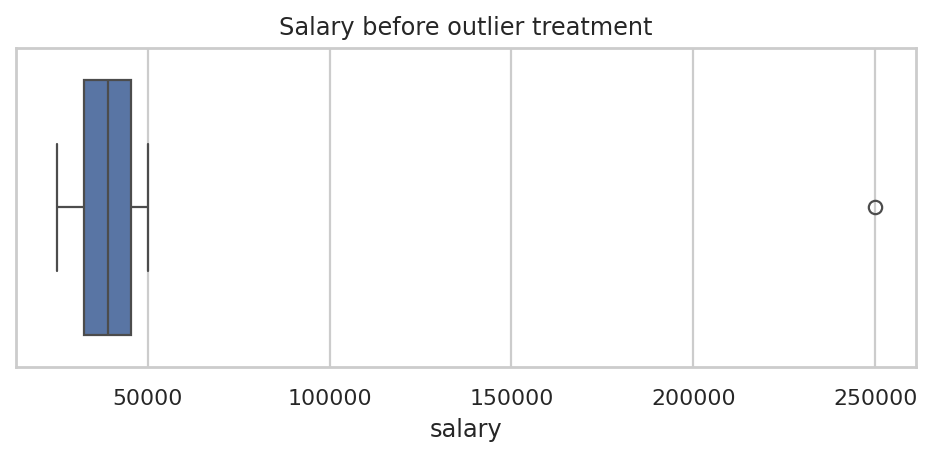

In [14]:
plt.figure(figsize=(6, 3))
sns.boxplot(x=clean["salary"])
plt.title("Salary before outlier treatment")
save_plot("13_boxplot")


**Observation:** The point beyond the whisker is a possible outlier, not automatically an error.

## Program 14: Visualize outliers using a Scatter Plot.

**Procedure:** Plot salary against experience.

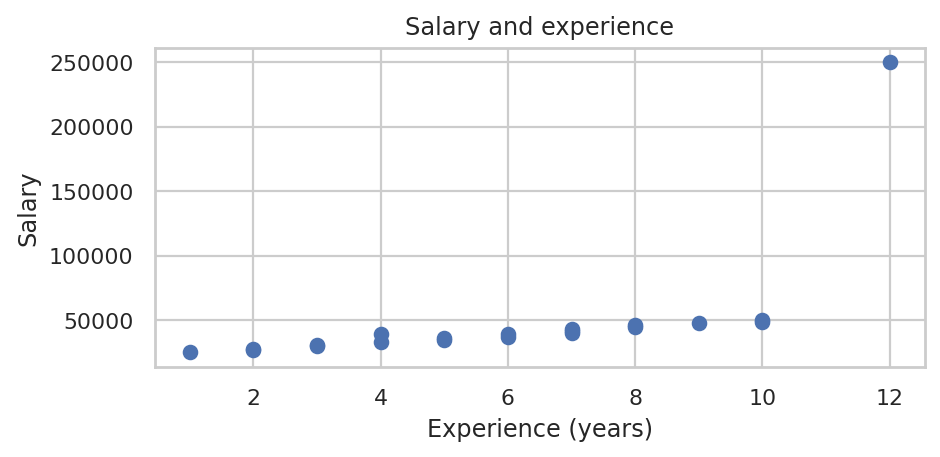

In [15]:
plt.figure(figsize=(6, 3))
plt.scatter(clean["experience"], clean["salary"])
plt.xlabel("Experience (years)")
plt.ylabel("Salary")
plt.title("Salary and experience")
save_plot("14_scatter")


**Observation:** The extreme salary is separated from the main group of observations.

## Program 15: Remove outliers using the IQR method.

**Procedure:** Exclude rows outside the IQR limits and save a checkpoint.

In [16]:
no_outliers = clean.loc[~outlier_mask].copy()
print("Rows before:", len(clean))
print("Rows after:", len(no_outliers))
no_outliers.to_csv(OUT / "outliers_removed.csv", index=False)


Rows before: 20
Rows after: 19


**Observation:** Removing the flagged row reduces the sample size.

## Program 16: Replace outliers with the median value.

**Procedure:** Copy the data and replace outlier salaries with the non-outlier median.

In [17]:
replaced = clean.copy()
replacement = clean.loc[~outlier_mask, "salary"].median()
replaced.loc[outlier_mask, "salary"] = replacement
print("Replacement median:", replacement)
print(replaced.loc[outlier_mask, ["salary", "experience"]])


Replacement median: 39000.0
      salary  experience
13 39000.000          12


**Observation:** The replacement is calculated from salaries that were not flagged.

## Program 17: Cap outliers using percentile-based capping.

**Procedure:** Find the 5th and 95th percentiles and clip salary to these limits.

In [18]:
capped = clean.copy()
low, high = capped["salary"].quantile([0.05, 0.95])
capped["salary"] = capped["salary"].clip(low, high)
print("5th and 95th percentile:", low, high)
print("New salary range:", capped["salary"].min(),
      capped["salary"].max())


5th and 95th percentile: 26900.0 60000.000000000146
New salary range: 26900.0 60000.000000000146


**Observation:** Percentile capping changes both tails without removing records.

## Program 18: Compare the dataset before and after outlier treatment.

**Procedure:** Compare descriptive statistics for four salary versions.

In [19]:
print(pd.DataFrame({"original": clean["salary"].describe(),
                    "removed": no_outliers["salary"].describe(),
                    "replaced": replaced["salary"].describe(),
                    "capped": capped["salary"].describe()}))


        original   removed  replaced    capped
count     20.000    19.000    20.000    20.000
mean   48650.000 38052.632 38100.000 39245.000
std    47981.658  7699.016  7496.666  8808.517
min    25000.000 25000.000 25000.000 26900.000
25%    32500.000 32000.000 32500.000 32500.000
50%    39000.000 39000.000 39000.000 39000.000
75%    45250.000 44000.000 43500.000 45250.000
max   250000.000 50000.000 50000.000 60000.000


**Observation:** Different treatments affect the mean, spread, and maximum salary differently.

## Program 19: Apply Min-Max Normalization to numerical features.

**Procedure:** Fit MinMaxScaler on the demonstration features and transform them.

In [20]:
from sklearn.preprocessing import MinMaxScaler
features = replaced[["age", "salary", "experience"]].copy()
minmax = pd.DataFrame(MinMaxScaler().fit_transform(features),
                      columns=features.columns)
print(minmax.head())
print("Minimums:", minmax.min().tolist())
print("Maximums:", minmax.max().tolist())


    age  salary  experience
0 0.000   0.000       0.000
1 0.214   0.200       0.182
2 0.429   0.400       0.364
3 0.643   0.600       0.545
4 0.929   1.000       0.818
Minimums: [0.0, 0.0, 0.0]
Maximums: [0.9999999999999998, 1.0, 0.9999999999999999]


**Observation:** Min-max scaling maps the observed feature range to 0 through 1.

## Program 20: Apply Standardization (Z-score Scaling).

**Procedure:** Apply StandardScaler and inspect the transformed mean and spread.

In [21]:
from sklearn.preprocessing import StandardScaler
standard = pd.DataFrame(StandardScaler().fit_transform(features),
                        columns=features.columns)
print(standard.head())
print("Means:", standard.mean().round(3).tolist())
print("Standard deviations:", standard.std(ddof=0).round(3).tolist())


     age  salary  experience
0 -1.767  -1.793      -1.683
1 -0.993  -1.109      -1.003
2 -0.219  -0.424      -0.323
3  0.555   0.260       0.357
4  1.586   1.629       1.377
Means: [-0.0, -0.0, -0.0]
Standard deviations: [1.0, 1.0, 1.0]


**Observation:** Standardized features have mean approximately zero and population standard deviation one.

## Program 21: Apply Robust Scaling to handle outliers.

**Procedure:** Apply RobustScaler to the data that still contains the extreme salary.

In [22]:
from sklearn.preprocessing import RobustScaler
robust = pd.DataFrame(RobustScaler().fit_transform(
    clean[["age", "salary", "experience"]]), columns=features.columns)
print(robust.head())
print("Outlier salary after scaling:", robust.loc[13, "salary"])


     age  salary  experience
0 -1.273  -1.098      -1.176
1 -0.727  -0.706      -0.706
2 -0.182  -0.314      -0.235
3  0.364   0.078       0.235
4  1.091   0.863       0.941
Outlier salary after scaling: 16.54901960784314


**Observation:** RobustScaler uses medians and quartiles but does not remove the outlier.

## Program 22: Apply Max Absolute Scaling.

**Procedure:** Fit and apply MaxAbsScaler.

In [23]:
from sklearn.preprocessing import MaxAbsScaler
maxabs = pd.DataFrame(MaxAbsScaler().fit_transform(features),
                      columns=features.columns)
print(maxabs.head())
print("Maximum absolute values:", maxabs.abs().max().tolist())


    age  salary  experience
0 0.611   0.500       0.083
1 0.694   0.600       0.250
2 0.778   0.700       0.417
3 0.861   0.800       0.583
4 0.972   1.000       0.833
Maximum absolute values: [1.0, 1.0, 1.0]


**Observation:** Each feature is divided by its maximum absolute value.

## Program 23: Compare original and normalized datasets.

**Procedure:** Display original salary beside its min-max scaled value.

In [24]:
print(pd.DataFrame({"original_salary": features["salary"],
                    "minmax_salary": minmax["salary"]}).head(8))


   original_salary  minmax_salary
0        25000.000          0.000
1        30000.000          0.200
2        35000.000          0.400
3        40000.000          0.600
4        50000.000          1.000
5        45000.000          0.800
6        39000.000          0.560
7        37000.000          0.480


**Observation:** Scaling changes the units while preserving the ordering of salaries.

## Program 24: Visualize the effect of normalization using histograms.

**Procedure:** Draw original and normalized salary histograms side by side.

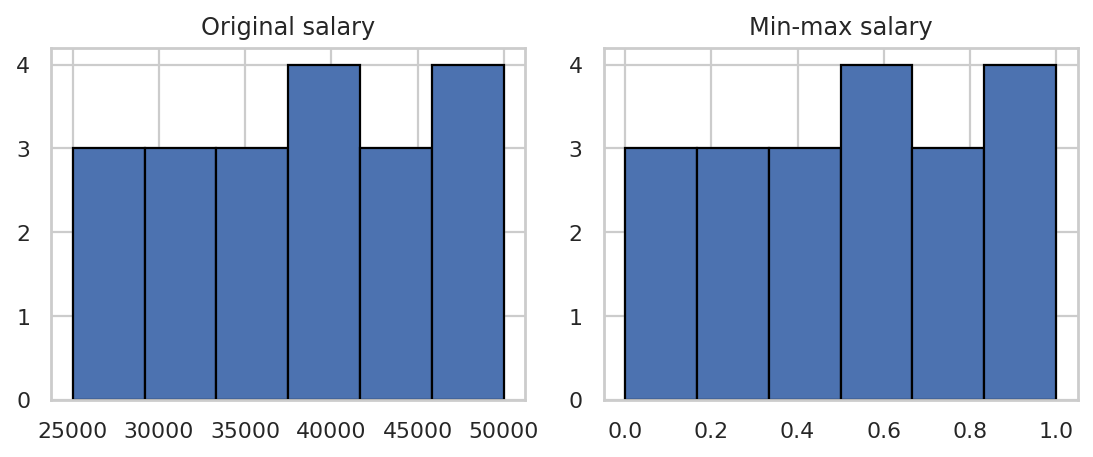

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].hist(features["salary"], bins=6, edgecolor="black")
axes[0].set_title("Original salary")
axes[1].hist(minmax["salary"], bins=6, edgecolor="black")
axes[1].set_title("Min-max salary")
save_plot("24_histograms")


**Observation:** The shape is preserved but the horizontal scale changes.

## Program 25: Visualize the effect of scaling using box plots.

**Procedure:** Draw box plots before and after standardization.

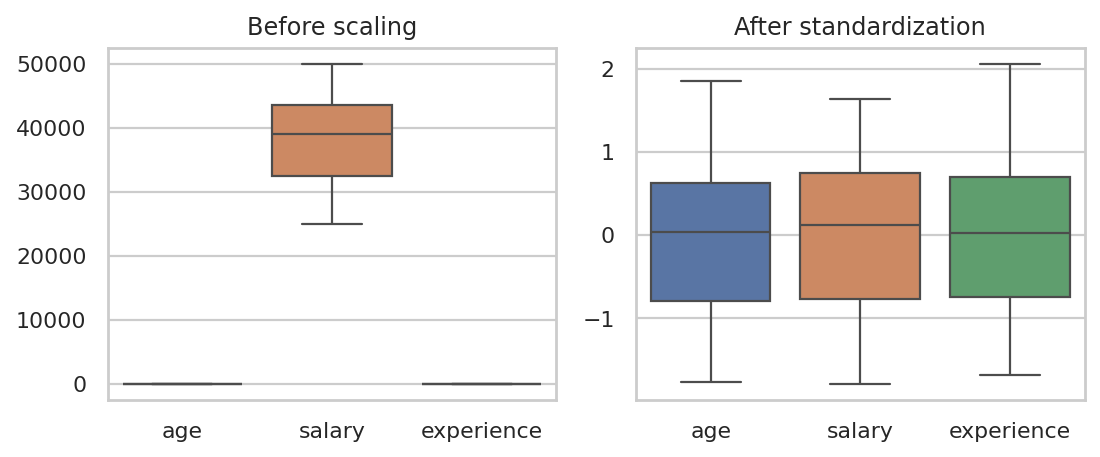

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
sns.boxplot(data=features, ax=axes[0])
axes[0].set_title("Before scaling")
sns.boxplot(data=standard, ax=axes[1])
axes[1].set_title("After standardization")
save_plot("25_scaling_boxplots")


**Observation:** Standardization lets features with different units be viewed on comparable scales.

## Program 26: Compare different scaling techniques on the same dataset.

**Procedure:** Compare salary values under the different transformations.

In [27]:
comparison = pd.DataFrame({
    "original": features["salary"],
    "minmax": minmax["salary"],
    "standard": standard["salary"],
    "robust": robust["salary"],
    "maxabs": maxabs["salary"]})
print(comparison.head(8))


   original  minmax  standard  robust  maxabs
0 25000.000   0.000    -1.793  -1.098   0.500
1 30000.000   0.200    -1.109  -0.706   0.600
2 35000.000   0.400    -0.424  -0.314   0.700
3 40000.000   0.600     0.260   0.078   0.800
4 50000.000   1.000     1.629   0.863   1.000
5 45000.000   0.800     0.944   0.471   0.900
6 39000.000   0.560     0.123   0.000   0.780
7 37000.000   0.480    -0.151  -0.157   0.740


**Observation:** Robust scaling here uses untreated data so its input still contains the outlier.

## Program 27: Encode categorical variables using Label Encoding.

**Procedure:** Fit LabelEncoder on department and print the mapping.

In [28]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
labels = encoder.fit_transform(clean["department"])
print("Mapping:", dict(zip(encoder.classes_,
                            range(len(encoder.classes_)))))
print("Encoded values:", labels)


Mapping: {'HR': 0, 'IT': 1, 'Sales': 2}
Encoded values: [1 0 2 1 2 0 1 1 1 0 2 1 0 2 1 0 2 1 0 2]


**Observation:** The numerical labels identify categories; they do not imply a ranking.

## Program 28: Encode categorical variables using One-Hot Encoding.

**Procedure:** Create dummy variables using get_dummies().

In [29]:
one_hot = pd.get_dummies(clean["department"],
                         prefix="dept", dtype=int)
print(one_hot.head(8))


   dept_HR  dept_IT  dept_Sales
0        0        1           0
1        1        0           0
2        0        0           1
3        0        1           0
4        0        0           1
5        1        0           0
6        0        1           0
7        0        1           0


**Observation:** One column is created for each department.

## Program 29: Perform Binary Encoding on categorical data.

**Procedure:** Assign positive integer category codes and extract their binary bits.

In [30]:
codes, categories = pd.factorize(clean["department"], sort=True)
# Reserve 0 for unknown categories; known categories start at 1.
codes = codes + 1
width = int(np.ceil(np.log2(len(categories) + 1)))
binary = pd.DataFrame({
    f"dept_bit_{bit}": (codes >> bit) & 1
    for bit in range(width)})
print("Categories:", categories.tolist())
print(binary.head(8))


Categories: ['HR', 'IT', 'Sales']
   dept_bit_0  dept_bit_1
0           0           1
1           1           0
2           1           1
3           0           1
4           1           1
5           1           0
6           0           1
7           0           1


**Observation:** Three categories can be represented with two binary columns.

## Program 30: Create a new feature by combining two existing columns.

**Procedure:** Divide salary by experience to create a combined feature.

In [31]:
engineered = replaced.copy()
engineered["salary_per_year"] = (
    engineered["salary"] / engineered["experience"].clip(lower=1))
print(engineered[["salary", "experience", "salary_per_year"]].head())


     salary  experience  salary_per_year
0 25000.000           1        25000.000
1 30000.000           3        10000.000
2 35000.000           5         7000.000
3 40000.000           7         5714.286
4 50000.000          10         5000.000


**Observation:** The denominator is kept above zero to avoid division by zero.

## Program 31: Extract year, month, and day from a date column.

**Procedure:** Parse joined as a date and extract year, month, and day.

In [32]:
dates = pd.to_datetime(original["joined"], errors="raise")
parts = pd.DataFrame({"year": dates.dt.year,
                      "month": dates.dt.month,
                      "day": dates.dt.day})
print(parts.head())


   year  month  day
0  2022      1    1
1  2022      2    1
2  2022      3    1
3  2022      4    1
4  2022      5    1


**Observation:** Datetime accessors separate the calendar components.

## Program 32: Create a new feature using mathematical transformations.

**Procedure:** Create a squared experience feature and a square-root salary feature.

In [33]:
transformed = replaced.copy()
transformed["experience_squared"] = transformed["experience"] ** 2
transformed["salary_sqrt"] = np.sqrt(transformed["salary"])
print(transformed[["experience", "experience_squared",
                   "salary_sqrt"]].head())


   experience  experience_squared  salary_sqrt
0           1                   1      158.114
1           3                   9      173.205
2           5                  25      187.083
3           7                  49      200.000
4          10                 100      223.607


**Observation:** Squared and square-root features can express nonlinear relationships.

## Program 33: Apply Log Transformation to skewed data.

**Procedure:** Compare salary skewness before and after log1p and draw a histogram.

Original skew: 4.291
Log skew: 3.116


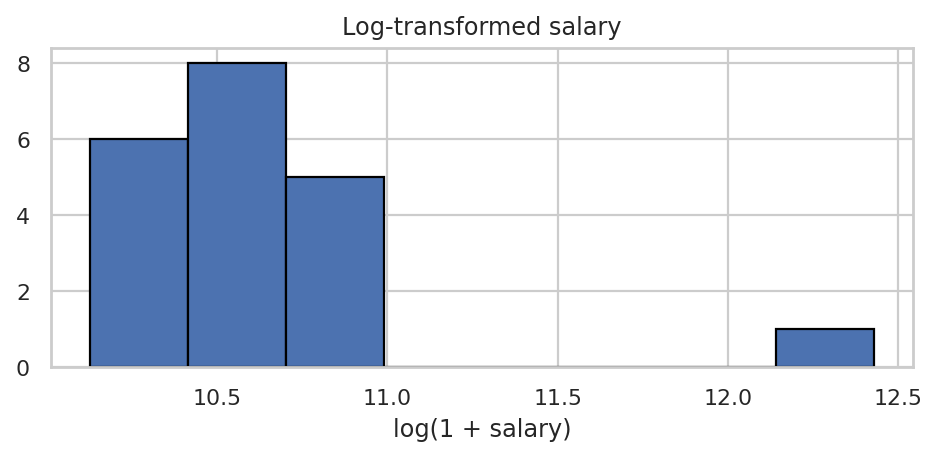

In [34]:
log_salary = np.log1p(clean["salary"])
print("Original skew:", round(clean["salary"].skew(), 3))
print("Log skew:", round(log_salary.skew(), 3))
plt.figure(figsize=(6, 3))
plt.hist(log_salary, bins=8, edgecolor="black")
plt.xlabel("log(1 + salary)")
plt.title("Log-transformed salary")
save_plot("33_log_salary")


**Observation:** The logarithm compresses high salaries; log1p is defined at zero.

## Program 34: Perform Feature Selection using correlation analysis.

**Procedure:** Calculate correlations with the target and apply an absolute threshold.

In [35]:
correlations = replaced[numeric].corr()["performance"].drop(
    "performance")
selected = correlations[correlations.abs() >= 0.60].index.tolist()
print("Correlation with performance:")
print(correlations)
print("Selected at |r| >= 0.60:", selected)


Correlation with performance:
age          0.963
salary       0.905
experience   0.985
Name: performance, dtype: float64
Selected at |r| >= 0.60: ['age', 'salary', 'experience']


**Observation:** This is exploratory selection on the teaching dataset; real predictive selection must use only training data.

## Program 35: Create a final preprocessed dataset ready for Machine Learning.

**Procedure:** Split the original dataset, fit preprocessing on training rows only, transform both splits, and save separate ML-ready CSV files.

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Split original rows before fitting any preprocessing step.
X = original[["age", "salary", "experience", "department"]]
y = original["performance"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)
numeric_columns = ["age", "salary", "experience"]
num_pipeline = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())])
cat_pipeline = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore",
                             sparse_output=False))])
processor = ColumnTransformer([
    ("num", num_pipeline, numeric_columns),
    ("cat", cat_pipeline, ["department"])])
train_array = processor.fit_transform(X_train)
test_array = processor.transform(X_test)
names = processor.get_feature_names_out()
train_ready = pd.DataFrame(train_array, columns=names)
test_ready = pd.DataFrame(test_array, columns=names)
train_ready["performance"] = y_train.to_numpy()
test_ready["performance"] = y_test.to_numpy()
train_ready.to_csv(OUT / "train_preprocessed.csv", index=False)
test_ready.to_csv(OUT / "test_preprocessed.csv", index=False)
print("Train:", train_ready.shape, "Test:", test_ready.shape)
print("Remaining missing values:",
      train_ready.isna().sum().sum() + test_ready.isna().sum().sum())
print(train_ready.head(3))


Train: (15, 7) Test: (5, 7)
Remaining missing values: 0
   num__age  num__salary  num__experience  cat__department_HR  \
0    -0.058       -0.145            0.682               1.000   
1    -0.638       -0.371           -0.834               0.000   
2     0.522       -0.239            0.303               0.000   

   cat__department_IT  cat__department_Sales  performance  
0               0.000                  0.000           74  
1               1.000                  0.000           65  
2               1.000                  0.000           70  


**Observation:** Training rows alone determine imputation, scaling, and categories. The untouched test split is transformed with the same fitted processor.